In [1]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [2]:
RANDOM_SEED = 42

def set_seeds(seed: int=RANDOM_SEED) -> None:
    """Sets random sets for torch operations.

    Args:
        seed (int, optional): Random seed to set. Defaults to 42.
    """
    torch.manual_seed(RANDOM_SEED)
    torch.cuda.manual_seed(RANDOM_SEED)

# 1. Get Data

In [12]:
import os
import zipfile

from pathlib import Path

import requests

def download_data(source: str, 
                  destination: str,
                  remove_source: bool = True) -> Path:
    """Downloads a zipped dataset from source and unzips to destination.

    Args:
        source (str): A link to a zipped file containing data.
        destination (str): A target directory to unzip data to.
        remove_source (bool): Whether to remove the source after downloading and extracting.
    
    Returns:
        pathlib.Path to downloaded data.
    
    Example usage:
        download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                      destination="pizza_steak_sushi")
    """
    # Setup path to data folder
    data_path = Path("data/")
    image_path = data_path / destination

    # If the image folder doesn't exist, download it and prepare it... 
    if image_path.is_dir():
        print(f"[INFO] {image_path} directory exists, skipping download.")
    else:
        print(f"[INFO] Did not find {image_path} directory, creating one...")
        image_path.mkdir(parents=True, exist_ok=True)
        
        # Download pizza, steak, sushi data
        target_file = Path(source).name
        with open(data_path / target_file, "wb") as f:
            request = requests.get(source)
            print(f"[INFO] Downloading {target_file} from {source}...")
            f.write(request.content)

        # Unzip pizza, steak, sushi data
        with zipfile.ZipFile(data_path / target_file, "r") as zip_ref:
            print(f"[INFO] Unzipping {target_file} data...") 
            zip_ref.extractall(image_path)

        # Remove .zip file
        if remove_source:
            os.remove(data_path / target_file)
    
    return image_path

image_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                           destination="pizza_steak_sushi")
image_path

[INFO] data\pizza_steak_sushi directory exists, skipping download.


WindowsPath('data/pizza_steak_sushi')

# 2. Get dataloaders

In [3]:
from going_modular import engine, data_setup
from pathlib import Path
import torchvision.transforms.v2 as T
import torchvision

DATA_DIR = Path("data/")
IMAGE_DIR = DATA_DIR / "pizza_steak_sushi"
TRAIN_DIR = IMAGE_DIR / "train"
TEST_DIR = IMAGE_DIR / "test"

weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT

BATCH_SIZE = 32

train_dataloader, test_dataloader, class_names = data_setup.create_dataloaders(
    TRAIN_DIR, TEST_DIR, weights.transforms(), BATCH_SIZE, 0
)
train_dataloader, test_dataloader, class_names, weights.transforms()

(<torch.utils.data.dataloader.DataLoader at 0x20321d989e0>,
 ['pizza', 'steak', 'sushi'],
 ImageClassification(
     crop_size=[224]
     resize_size=[256]
     mean=[0.485, 0.456, 0.406]
     std=[0.229, 0.224, 0.225]
     interpolation=InterpolationMode.BICUBIC
 ))

# 3. Get Pretrained Model

In [4]:
model = torchvision.models.efficientnet_b0(weights=weights).to(device)

for param in model.features.parameters():
    param.requires_grad = False

In [5]:
model.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)

In [6]:
from torch import nn

model.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features=1280, out_features=len(class_names), bias=True)
).to(device)
model.classifier

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=3, bias=True)
)

In [7]:
from torchinfo import summary

summary(model= model,
        input_size=(BATCH_SIZE, 3, 224, 224),
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

# 4. Train Model and Track Results

## 4.1 loss function and optimizer

In [8]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## 4.2 Adjust `train.py` to use `SummaryWriter()`

In [9]:
from torch.utils.tensorboard import SummaryWriter

writer = SummaryWriter()
writer

可以用`SummaryWriter`的`add_scalars(main_tag: str, tag_scalar_dict: Dict)` 来记录各种值, 比如`train()`过程中的 loss 与 acc
- `main_tag`: 标签, 如`Accuracy`
- `tag_scalar_dict`: 字典, 记录不同的值, 如`{'train_loss': train_loss, 'train_accuracy': train_acc}`

使用结束后, 需要用`writer.close()`来关闭`SummaryWriter()`对象, 否则可能会出现数据丢失的情况

后续我直接在train.py进行了修改

In [12]:
from going_modular import engine
model_results = engine.train(model, train_dataloader, test_dataloader, optimizer, loss_fn, 5, device)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0725 | train_acc: 0.3906 | test_loss: 0.9006 | test_acc: 0.7538
Epoch: 2 | train_loss: 0.9408 | train_acc: 0.6367 | test_loss: 0.7061 | test_acc: 0.8333
Epoch: 3 | train_loss: 0.7644 | train_acc: 0.7148 | test_loss: 0.7073 | test_acc: 0.7746
Epoch: 4 | train_loss: 0.6733 | train_acc: 0.9023 | test_loss: 0.6606 | test_acc: 0.8049
Epoch: 5 | train_loss: 0.6017 | train_acc: 0.8906 | test_loss: 0.5794 | test_acc: 0.8248


In [13]:
model_results

{'train_loss': [1.0724604055285454,
  0.9408217146992683,
  0.7643843740224838,
  0.6733400896191597,
  0.6016860604286194],
 'train_acc': [0.390625, 0.63671875, 0.71484375, 0.90234375, 0.890625],
 'test_loss': [0.9005876978238424,
  0.7060898145039877,
  0.7073261539141337,
  0.6605505545934042,
  0.5793638626734415],
 'test_acc': [0.7537878787878788,
  0.8333333333333334,
  0.774621212121212,
  0.8049242424242425,
  0.8248106060606061]}

# 5. View results in TensorBoard

VSCode: Ctrl+Shift+P 搜索 `Python: Launch TensorBoard`
- PS: 需要安装 TensorBoard 插件, 以及在虚拟环境中安装 tensorboard 包

In [14]:
# jupyter 方法
%load_ext tensorboard
# %reload_ext tensorboard
%tensorboard --logdir=runs
# 运行后到 http://localhost:6006/#timeseries 查看

Reusing TensorBoard on port 6007 (pid 26360), started 5:26:27 ago. (Use '!kill 26360' to kill it.)

# 6. 创建一个custom的`SummaryWriter`

In [10]:
def create_writer(experiment_name: str, 
                  model_name: str, 
                  extra: str | None=None) -> SummaryWriter():
    """Creates a torch.utils.tensorboard.writer.SummaryWriter() instance saving to a specific log_dir.

    log_dir is a combination of runs/timestamp/experiment_name/model_name/extra.

    Where timestamp is the current date in YYYY-MM-DD format.

    Args:
        experiment_name (str): Name of experiment.
        model_name (str): Name of model.
        extra (str, optional): Anything extra to add to the directory. Defaults to None.

    Returns:
        torch.utils.tensorboard.writer.SummaryWriter(): Instance of a writer saving to log_dir.

    Example usage:
        # Create a writer saving to "runs/2022-06-04/data_10_percent/effnetb2/5_epochs/"
        writer = create_writer(experiment_name="data_10_percent",
                               model_name="effnetb2",
                               extra="5_epochs")
        # The above is the same as:
        writer = SummaryWriter(log_dir="runs/2022-06-04/data_10_percent/effnetb2/5_epochs/")
    """
    from datetime import datetime
    import os

    # Get timestamp of current date (all experiments on certain day live in same folder)
    timestamp = datetime.now().strftime("%Y-%m-%d") # returns current date in YYYY-MM-DD format

    if extra:
        # Create log directory path
        log_dir = os.path.join("runs", timestamp, experiment_name, model_name, extra)
    else:
        log_dir = os.path.join("runs", timestamp, experiment_name, model_name)
        
    print(f"[INFO] Created SummaryWriter, saving to: {log_dir}...")
    
    return SummaryWriter(log_dir=log_dir)

In [16]:
example_writer = create_writer(experiment_name="data_10_percent",
                               model_name="effnetb0",
                               extra="5_epochs")

[INFO] Created SummaryWriter, saving to: runs\2026-07-09\data_10_percent\effnetb0\5_epochs...


# 7. Setting up a series of modelling experiments

In [13]:
# Download 10 percent and 20 percent training data (if necessary)
data_10_percent_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip",
                                     destination="pizza_steak_sushi")

data_20_percent_path = download_data(source="https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip",
                                     destination="pizza_steak_sushi_20_percent")

[INFO] data\pizza_steak_sushi directory exists, skipping download.
[INFO] data\pizza_steak_sushi_20_percent directory exists, skipping download.


In [14]:
# Setup training directory paths
train_dir_10_percent = data_10_percent_path / "train"
train_dir_20_percent = data_20_percent_path / "train"

# 使用同一个测试集
test_dir = data_10_percent_path / "test"

# Check the directories
print(f"Training directory 10%: {train_dir_10_percent}")
print(f"Training directory 20%: {train_dir_20_percent}")
print(f"Testing directory: {test_dir}")

Training directory 10%: data\pizza_steak_sushi\train
Training directory 20%: data\pizza_steak_sushi_20_percent\train
Testing directory: data\pizza_steak_sushi\test


In [15]:
import torchvision.transforms.v2 as T

# Create a transform to normalize data distribution to be inline with ImageNet
normalize = T.Normalize(mean=[0.485, 0.456, 0.406], # values per colour channel [red, green, blue]
                            std=[0.229, 0.224, 0.225]) # values per colour channel [red, green, blue]

# Compose transforms into a pipeline
simple_transform = T.Compose([
    T.Resize((224, 224)),
    T.ToImage(),
    T.ToDtype(torch.float32, True),
    normalize # 3. Normalize the images so their distributions match the ImageNet dataset 
])

In [16]:
# Create 10% training and test DataLoaders
train_dataloader_10_percent, test_dataloader, class_names = data_setup.create_dataloaders(train_dir=train_dir_10_percent,
    test_dir=test_dir, 
    transform=simple_transform,
    batch_size=BATCH_SIZE
)

# Create 20% training and test data DataLoders
train_dataloader_20_percent, test_dataloader, _ = data_setup.create_dataloaders(train_dir=train_dir_20_percent,
    test_dir=test_dir,
    transform=simple_transform,
    batch_size=BATCH_SIZE
)

# Find the number of samples/batches per dataloader (using the same test_dataloader for both experiments)
print(f"Number of batches of size {BATCH_SIZE} in 10 percent training data: {len(train_dataloader_10_percent)}")
print(f"Number of batches of size {BATCH_SIZE} in 20 percent training data: {len(train_dataloader_20_percent)}")
print(f"Number of batches of size {BATCH_SIZE} in testing data: {len(test_dataloader)} (all experiments will use the same test set)")
print(f"Number of classes: {len(class_names)}, class names: {class_names}")

Number of batches of size 32 in 10 percent training data: 8
Number of batches of size 32 in 20 percent training data: 15
Number of batches of size 32 in testing data: 3 (all experiments will use the same test set)
Number of classes: 3, class names: ['pizza', 'steak', 'sushi']


In [21]:
eff_weights = b2 = torchvision.models.EfficientNet_B2_Weights.DEFAULT
eff_b2_model = torchvision.models.efficientnet_b2(weights=eff_weights)

Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to C:\Users\81456/.cache\torch\hub\checkpoints\efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:01<00:00, 30.7MB/s]


In [17]:
from torchvision.models import EfficientNet
# Get num out features (one for each class pizza, steak, sushi)
OUT_FEATURES = len(class_names)

# Create an EffNetB0 feature extractor
def create_effnetb0() -> EfficientNet:
    # 1. Get the base model with pretrained weights and send to target device
    weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
    model = torchvision.models.efficientnet_b0(weights=weights).to(device)

    # 2. Freeze the base model layers
    for param in model.features.parameters():
        param.requires_grad = False

    # 3. Set the seeds
    set_seeds()

    # 4. Change the classifier head
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.2),
        nn.Linear(in_features=1280, out_features=OUT_FEATURES)
    ).to(device)

    return model

# Create an EffNetB2 feature extractor
def create_effnetb2()-> EfficientNet:
    # 1. Get the base model with pretrained weights and send to target device
    weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT
    model = torchvision.models.efficientnet_b2(weights=weights).to(device)

    # 2. Freeze the base model layers
    for param in model.features.parameters():
        param.requires_grad = False

    # 3. Set the seeds
    set_seeds()

    # 4. Change the classifier head
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(in_features=1408, out_features=OUT_FEATURES)
    ).to(device)

    return model

In [18]:
effnetb0 = create_effnetb0() 

# Get an output summary of the layers in our EffNetB0 feature extractor model (uncomment to view full output)
summary(model=effnetb0, 
        input_size=(32, 3, 224, 224), # make sure this is "input_size", not "input_shape"
        # col_names=["input_size"], # uncomment for smaller output
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
) 

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [19]:
effnetb2 = create_effnetb2() 

# Get an output summary of the layers in our EffNetB0 feature extractor model (uncomment to view full output)
summary(model=effnetb2, 
        input_size=(32, 3, 224, 224), # make sure this is "input_size", not "input_shape"
        # col_names=["input_size"], # uncomment for smaller output
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
) 

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1408, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [20]:
# 1. Create epochs list
num_epochs = [5, 10]

# 2. Create models list (need to create a new model for each experiment)
models = {"effnetb0": effnetb0, "effnetb2": effnetb2}

# 3. Create dataloaders dictionary for various dataloaders
train_dataloaders = {"data_10_percent": train_dataloader_10_percent,
                     "data_20_percent": train_dataloader_20_percent}

In [30]:
from going_modular import utils
from going_modular import engine

experiment_number = 0

for dataloader_name, train_dataloader in train_dataloaders.items():
    for epochs in num_epochs:
        for (model_name, model) in models.items():
            experiment_number += 1
            print(f"[INFO] Experiment number: {experiment_number}")
            print(f"[INFO] Model: {model_name}")
            print(f"[INFO] DataLoader: {dataloader_name}")
            print(f"[INFO] Number of epochs: {epochs}")
            
            loss_fn = nn.CrossEntropyLoss()
            optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
            
            engine.train(model, train_dataloader, test_dataloader, optimizer, loss_fn, epochs, device, writer=create_writer(dataloader_name, model_name, f"{epochs} epochs"))
            save_filepath = f"07_{model_name}_{dataloader_name}_{epochs}_epochs.pth"
            utils.save_model(model=model,
                       target_dir="models",
                       model_name=save_filepath)
            print("-"*50 + "\n")

[INFO] Experiment number: 1
[INFO] Model: effnetb0
[INFO] DataLoader: data_10_percent
[INFO] Number of epochs: 5
[INFO] Created SummaryWriter, saving to: runs\2026-07-09\data_10_percent\effnetb0\5 epochs...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0858 | train_acc: 0.3477 | test_loss: 0.8985 | test_acc: 0.5189
Epoch: 2 | train_loss: 0.8590 | train_acc: 0.6953 | test_loss: 0.6936 | test_acc: 0.8239
Epoch: 3 | train_loss: 0.8601 | train_acc: 0.6133 | test_loss: 0.6447 | test_acc: 0.8655
Epoch: 4 | train_loss: 0.7057 | train_acc: 0.8516 | test_loss: 0.6684 | test_acc: 0.8864
Epoch: 5 | train_loss: 0.6880 | train_acc: 0.7539 | test_loss: 0.6607 | test_acc: 0.7737
[INFO] Saving model to: models\07_effnetb0_data_10_percent_5_epochs.pth
--------------------------------------------------

[INFO] Experiment number: 2
[INFO] Model: effnetb2
[INFO] DataLoader: data_10_percent
[INFO] Number of epochs: 5
[INFO] Created SummaryWriter, saving to: runs\2026-07-09\data_10_percent\effnetb2\5 epochs...


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0422 | train_acc: 0.4062 | test_loss: 0.9485 | test_acc: 0.7017
Epoch: 2 | train_loss: 0.8523 | train_acc: 0.6719 | test_loss: 0.8747 | test_acc: 0.7434
Epoch: 3 | train_loss: 0.8746 | train_acc: 0.6055 | test_loss: 0.7825 | test_acc: 0.8456
Epoch: 4 | train_loss: 0.6919 | train_acc: 0.7695 | test_loss: 0.7172 | test_acc: 0.8570
Epoch: 5 | train_loss: 0.6375 | train_acc: 0.8906 | test_loss: 0.6391 | test_acc: 0.9280
[INFO] Saving model to: models\07_effnetb2_data_10_percent_5_epochs.pth
--------------------------------------------------

[INFO] Experiment number: 3
[INFO] Model: effnetb0
[INFO] DataLoader: data_10_percent
[INFO] Number of epochs: 10
[INFO] Created SummaryWriter, saving to: runs\2026-07-09\data_10_percent\effnetb0\10 epochs...


...

Epoch: 1 | train_loss: 0.4494 | train_acc: 0.8333 | test_loss: 0.4004 | test_acc: 0.9280
Epoch: 2 | train_loss: 0.4042 | train_acc: 0.8354 | test_loss: 0.3585 | test_acc: 0.9489
Epoch: 3 | train_loss: 0.3762 | train_acc: 0.8833 | test_loss: 0.4084 | test_acc: 0.9081
Epoch: 4 | train_loss: 0.3793 | train_acc: 0.8688 | test_loss: 0.3507 | test_acc: 0.9280
Epoch: 5 | train_loss: 0.2718 | train_acc: 0.9375 | test_loss: 0.4135 | test_acc: 0.8977
[INFO] Saving model to: models\07_effnetb2_data_20_percent_5_epochs.pth
--------------------------------------------------

[INFO] Experiment number: 7
[INFO] Model: effnetb0
[INFO] DataLoader: data_20_percent
[INFO] Number of epochs: 10
[INFO] Created SummaryWriter, saving to: runs\2026-07-09\data_20_percent\effnetb0\10 epochs...


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.2702 | train_acc: 0.9187 | test_loss: 0.2502 | test_acc: 0.9489
Epoch: 2 | train_loss: 0.2493 | train_acc: 0.9042 | test_loss: 0.2289 | test_acc: 0.9384
Epoch: 3 | train_loss: 0.2387 | train_acc: 0.9313 | test_loss: 0.2488 | test_acc: 0.9384
Epoch: 4 | train_loss: 0.2233 | train_acc: 0.9500 | test_loss: 0.2252 | test_acc: 0.9280
Epoch: 5 | train_loss: 0.1972 | train_acc: 0.9604 | test_loss: 0.2285 | test_acc: 0.9384
Epoch: 6 | train_loss: 0.3205 | train_acc: 0.9208 | test_loss: 0.2204 | test_acc: 0.9176
Epoch: 7 | train_loss: 0.2396 | train_acc: 0.9167 | test_loss: 0.2422 | test_acc: 0.9384
Epoch: 8 | train_loss: 0.2597 | train_acc: 0.9062 | test_loss: 0.2328 | test_acc: 0.9384
Epoch: 9 | train_loss: 0.1854 | train_acc: 0.9458 | test_loss: 0.2462 | test_acc: 0.9489
Epoch: 10 | train_loss: 0.2002 | train_acc: 0.9250 | test_loss: 0.2167 | test_acc: 0.9384
[INFO] Saving model to: models\07_effnetb0_data_20_percent_10_epochs.pth
------------------------------------

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 0.3520 | train_acc: 0.8667 | test_loss: 0.3663 | test_acc: 0.9384
Epoch: 2 | train_loss: 0.2226 | train_acc: 0.9521 | test_loss: 0.3533 | test_acc: 0.9280
Epoch: 3 | train_loss: 0.2488 | train_acc: 0.9396 | test_loss: 0.3462 | test_acc: 0.9489
Epoch: 4 | train_loss: 0.2655 | train_acc: 0.9333 | test_loss: 0.3618 | test_acc: 0.9081
Epoch: 5 | train_loss: 0.3400 | train_acc: 0.8750 | test_loss: 0.3538 | test_acc: 0.9280
Epoch: 6 | train_loss: 0.3025 | train_acc: 0.9187 | test_loss: 0.3981 | test_acc: 0.8977
Epoch: 7 | train_loss: 0.2283 | train_acc: 0.9375 | test_loss: 0.3475 | test_acc: 0.9280
Epoch: 8 | train_loss: 0.2042 | train_acc: 0.9583 | test_loss: 0.3634 | test_acc: 0.8769
Epoch: 9 | train_loss: 0.2873 | train_acc: 0.9375 | test_loss: 0.3793 | test_acc: 0.8873
Epoch: 10 | train_loss: 0.2269 | train_acc: 0.9458 | test_loss: 0.3660 | test_acc: 0.9081
[INFO] Saving model to: models\07_effnetb2_data_20_percent_10_epochs.pth
------------------------------------

# 8. View experiments in TensorBoard

In [21]:
%reload_ext tensorboard
%tensorboard --logdir runs

Reusing TensorBoard on port 6006 (pid 15008), started 8:54:10 ago. (Use '!kill 15008' to kill it.)

# 9. Load in the best model and make predictions with it

In [24]:
eff_b2_model_loaded = create_effnetb2().to(device)
eff_b2_model_loaded.load_state_dict(torch.load("models/07_effnetb2_data_20_percent_10_epochs.pth"))
eff_b2_model_loaded

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          

In [28]:
eff_b2_model_loaded_size = Path("models/07_effnetb2_data_20_percent_10_epochs.pth").stat().st_size // (1024 * 1024)
print(f"model [models/07_effnetb2_data_20_percent_10_epochs.pth] is {eff_b2_model_loaded_size} MB large")

model [models/07_effnetb2_data_20_percent_10_epochs.pth] is 29 MB large


In [34]:
test_image_path_list = list(Path(TEST_DIR).glob("*/*.jpg"))
test_image_path_list[:5]

[WindowsPath('data/pizza_steak_sushi/test/pizza/1152100.jpg'),
 WindowsPath('data/pizza_steak_sushi/test/pizza/1503858.jpg'),
 WindowsPath('data/pizza_steak_sushi/test/pizza/1687143.jpg'),
 WindowsPath('data/pizza_steak_sushi/test/pizza/1925494.jpg'),
 WindowsPath('data/pizza_steak_sushi/test/pizza/194643.jpg')]

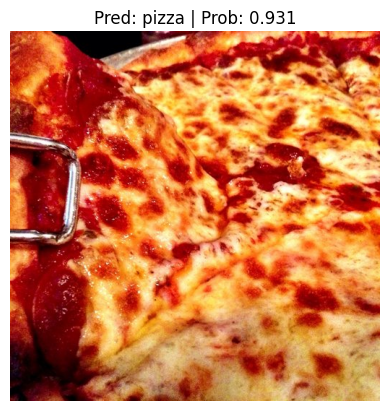

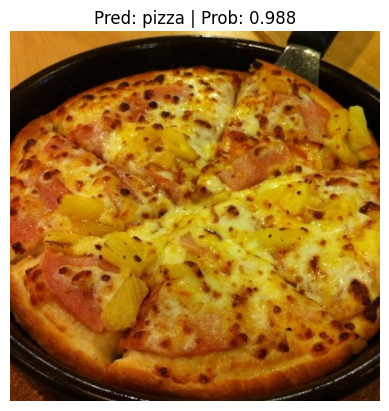

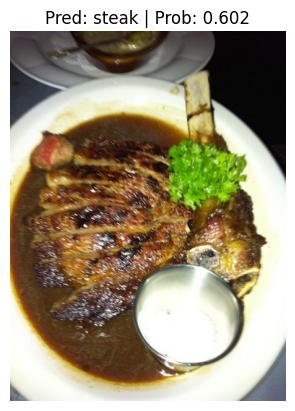

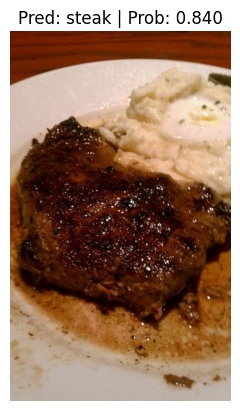

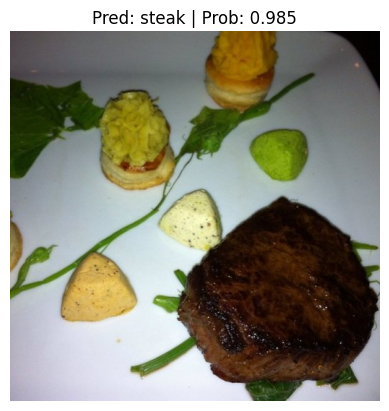

In [45]:
from going_modular import predictions
import random
random.seed(RANDOM_SEED)

random_image_list = random.sample(test_image_path_list, k=5)

for image_path in random_image_list:
    predictions.pred_and_plot_image(eff_b2_model_loaded, image_path, class_names, (224, 224), simple_transform)

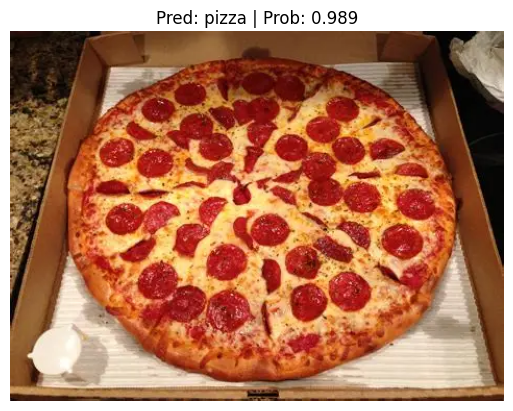

In [46]:
custom_image_path = DATA_DIR / "test_pizza.png"
predictions.pred_and_plot_image(eff_b2_model_loaded, custom_image_path, class_names, (224, 224), simple_transform)